### Some necessary packages

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

### Loading the meteorological datasets related to wind
- The dataset is a 4-D
- The forecast is 93 steps ahead(valid datetime)
- The model had been updated 4467 times(the ref datetime)
- There are six locations
- The data variables are:
    * temperature
    * Humidity
    * wind speed
    * wind speed at 100m
    * wind direction
    * wind direction at 100m

In [2]:
ds_wind=xr.open_dataset("dwd_icon_eu_hornsea_1_20200920_20231027.nc")
ds_wind

<xarray.Dataset> Size: 359MB
Dimensions:            (ref_datetime: 4467, valid_datetime: 93, latitude: 6,
                        longitude: 6)
Coordinates:
  * latitude           (latitude) float64 48B 53.77 53.84 53.9 53.97 54.03 54.1
  * longitude          (longitude) float64 48B 1.702 1.767 1.832 ... 1.962 2.027
  * ref_datetime       (ref_datetime) datetime64[ns] 36kB 2020-09-20 ... 2023...
  * valid_datetime     (valid_datetime) int64 744B 0 1 2 3 4 ... 111 114 117 120
Data variables:
    RelativeHumidity   (ref_datetime, valid_datetime, latitude, longitude) float32 60MB ...
    Temperature        (ref_datetime, valid_datetime, latitude, longitude) float32 60MB ...
    WindDirection      (ref_datetime, valid_datetime, latitude, longitude) float32 60MB ...
    WindDirection:100  (ref_datetime, valid_datetime, latitude, longitude) float32 60MB ...
    WindSpeed          (ref_datetime, valid_datetime, latitude, longitude) float32 60MB ...
    WindSpeed:100      (ref_datetime, valid_datetime, latitude, longitude) float32 60MB ...

### Loading the meteorological datasets for solar generation
- The dataset is a 4-D
- The forecast is 93 hours ahead(valid datetime)
- The model had been updated 4467 times(the ref datetime)
- There are six locations
- The data variables are:
    * CloudCover
    * SolarDownwardRadiation
    * Temperature

### Spatial Variation of Wind Speed Across Locations
- There are no significant differences in wind speeds across the locations

In [3]:
lat=ds_wind.WindSpeed.latitude.data
lon=ds_wind.WindSpeed.longitude.data
wind_speed=ds_wind.WindSpeed.data

### Taking a mean along the latitude and longitude dimentions(for wind inputs) 
- This reduces the data into a **2-D**(ref_datetime, valid datetime)

In [4]:
ds_wind_avg=ds_wind.mean(dim=['latitude','longitude'])
ds_wind_avg

<xarray.Dataset> Size: 10MB
Dimensions:            (ref_datetime: 4467, valid_datetime: 93)
Coordinates:
  * ref_datetime       (ref_datetime) datetime64[ns] 36kB 2020-09-20 ... 2023...
  * valid_datetime     (valid_datetime) int64 744B 0 1 2 3 4 ... 111 114 117 120
Data variables:
    RelativeHumidity   (ref_datetime, valid_datetime) float32 2MB 85.21 ... 7...
    Temperature        (ref_datetime, valid_datetime) float32 2MB 15.42 ... 1...
    WindDirection      (ref_datetime, valid_datetime) float32 2MB 61.59 ... 2...
    WindDirection:100  (ref_datetime, valid_datetime) float32 2MB 62.09 ... 2...
    WindSpeed          (ref_datetime, valid_datetime) float32 2MB 10.04 ... 5...
    WindSpeed:100      (ref_datetime, valid_datetime) float32 2MB 11.8 ... 5.556

### Preparing the dataset for machine learning models
- For each forecast run we have **93** values:
   - each forecast run should be repeated **93** times
   - the pattern of the lead hours should be repeated **4467** times 

In [5]:
ds_stacked=ds_wind_avg.stack(sample=('ref_datetime','valid_datetime'))
ds_stacked

<xarray.Dataset> Size: 20MB
Dimensions:            (sample: 415431)
Coordinates:
  * sample             (sample) object 3MB MultiIndex
  * ref_datetime       (sample) datetime64[ns] 3MB 2020-09-20 ... 2023-10-27
  * valid_datetime     (sample) int64 3MB 0 1 2 3 4 5 ... 108 111 114 117 120
Data variables:
    RelativeHumidity   (sample) float32 2MB 85.21 84.81 83.9 ... 80.46 79.41
    Temperature        (sample) float32 2MB 15.42 15.41 15.49 ... 12.89 13.03
    WindDirection      (sample) float32 2MB 61.59 60.82 60.2 ... 267.2 243.8
    WindDirection:100  (sample) float32 2MB 62.09 61.37 60.85 ... 267.3 243.9
    WindSpeed          (sample) float32 2MB 10.04 9.767 9.495 ... 6.098 5.026
    WindSpeed:100      (sample) float32 2MB 11.8 11.5 11.21 ... 6.106 6.73 5.556

In [6]:
df_wind=ds_stacked.to_dataframe()
df_wind

RelativeHumidity  Temperature  WindDirection  \
ref_datetime valid_datetime                                                 
2020-09-20   0                      85.213753    15.416670      61.588081   
             1                      84.810783    15.408349      60.819256   
             2                      83.904999    15.494086      60.202793   
             3                      82.977669    15.459883      56.277557   
             4                      82.238251    15.506005      54.625359   
...                                       ...          ...            ...   
2023-10-27   108                    85.169495    12.467031     258.679993   
             111                    86.336761    12.294271     288.635559   
             114                    80.832611    12.715936     290.076538   
             117                    80.463524    12.888119     267.246643   
             120                    79.409302    13.030528     243.840881   

                             WindDirection:100  WindSpeed  WindSpeed:100  \
ref_datetime valid_datetime                                                
2020-09-20   0                       62.085171  10.043627      11.802604   
             1                       61.368782   9.767446      11.495032   
             2                       60.853313   9.494630      11.213223   
             3                       57.054363   9.455198      11.135883   
             4                       55.247116   9.515404      11.254492   
...                                        ...        ...            ...   
2023-10-27   108                    258.742950   3.495213       3.701586   
             111                    288.763794   6.475207       7.006474   
             114                    290.225403   5.601550       6.105711   
             117                    267.324860   6.097645       6.729563   
             120                    243.856125   5.025548       5.556175   

                            ref_datetime  valid_datetime  
ref_datetime valid_datetime                               
2020-09-20   0                2020-09-20               0  
             1                2020-09-20               1  
             2                2020-09-20               2  
             3                2020-09-20               3  
             4                2020-09-20               4  
...                                  ...             ...  
2023-10-27   108              2023-10-27             108  
             111              2023-10-27             111  
             114              2023-10-27             114  
             117              2023-10-27             117  
             120              2023-10-27             120  

[415431 rows x 8 columns]

In [7]:
df_wind=df_wind.drop(columns=['ref_datetime','valid_datetime'])
df_wind

RelativeHumidity  Temperature  WindDirection  \
ref_datetime valid_datetime                                                 
2020-09-20   0                      85.213753    15.416670      61.588081   
             1                      84.810783    15.408349      60.819256   
             2                      83.904999    15.494086      60.202793   
             3                      82.977669    15.459883      56.277557   
             4                      82.238251    15.506005      54.625359   
...                                       ...          ...            ...   
2023-10-27   108                    85.169495    12.467031     258.679993   
             111                    86.336761    12.294271     288.635559   
             114                    80.832611    12.715936     290.076538   
             117                    80.463524    12.888119     267.246643   
             120                    79.409302    13.030528     243.840881   

                             WindDirection:100  WindSpeed  WindSpeed:100  
ref_datetime valid_datetime                                               
2020-09-20   0                       62.085171  10.043627      11.802604  
             1                       61.368782   9.767446      11.495032  
             2                       60.853313   9.494630      11.213223  
             3                       57.054363   9.455198      11.135883  
             4                       55.247116   9.515404      11.254492  
...                                        ...        ...            ...  
2023-10-27   108                    258.742950   3.495213       3.701586  
             111                    288.763794   6.475207       7.006474  
             114                    290.225403   5.601550       6.105711  
             117                    267.324860   6.097645       6.729563  
             120                    243.856125   5.025548       5.556175  

[415431 rows x 6 columns]

In [8]:
df_wind=df_wind.reset_index().copy()
df_wind

,ref_datetime,valid_datetime,RelativeHumidity,Temperature,WindDirection,WindDirection:100,WindSpeed,WindSpeed:100
0,2020-09-20,0,85.213753,15.416670,61.588081,62.085171,10.043627,11.802604
1,2020-09-20,1,84.810783,15.408349,60.819256,61.368782,9.767446,11.495032
2,2020-09-20,2,83.904999,15.494086,60.202793,60.853313,9.494630,11.213223
3,2020-09-20,3,82.977669,15.459883,56.277557,57.054363,9.455198,11.135883
4,2020-09-20,4,82.238251,15.506005,54.625359,55.247116,9.515404,11.254492
...,...,...,...,...,...,...,...,...
415426,2023-10-27,108,85.169495,12.467031,258.679993,258.742950,3.495213,3.701586
415427,2023-10-27,111,86.336761,12.294271,288.635559,288.763794,6.475207,7.006474
415428,2023-10-27,114,80.832611,12.715936,290.076538,290.225403,5.601550,6.105711
415429,2023-10-27,117,80.463524,12.888119,267.246643,267.324860,6.097645,6.729563


In [9]:
df_wind.isna().sum()

ref_datetime           0
valid_datetime         0
RelativeHumidity     371
Temperature          371
WindDirection        370
WindDirection:100    338
WindSpeed            370
WindSpeed:100        338
dtype: int64

In [10]:
df_wind['valid_datetime_abs'] = df_wind['ref_datetime'] + pd.to_timedelta(df_wind['valid_datetime'],unit='h')
df_wind['valid_datetime_abs'] = df_wind['valid_datetime_abs'].dt.tz_localize('UTC') 
df_wind

,ref_datetime,valid_datetime,RelativeHumidity,Temperature,WindDirection,WindDirection:100,WindSpeed,WindSpeed:100,valid_datetime_abs
0,2020-09-20,0,85.213753,15.416670,61.588081,62.085171,10.043627,11.802604,2020-09-20 00:00:00+00:00
1,2020-09-20,1,84.810783,15.408349,60.819256,61.368782,9.767446,11.495032,2020-09-20 01:00:00+00:00
2,2020-09-20,2,83.904999,15.494086,60.202793,60.853313,9.494630,11.213223,2020-09-20 02:00:00+00:00
3,2020-09-20,3,82.977669,15.459883,56.277557,57.054363,9.455198,11.135883,2020-09-20 03:00:00+00:00
4,2020-09-20,4,82.238251,15.506005,54.625359,55.247116,9.515404,11.254492,2020-09-20 04:00:00+00:00
...,...,...,...,...,...,...,...,...,...
415426,2023-10-27,108,85.169495,12.467031,258.679993,258.742950,3.495213,3.701586,2023-10-31 12:00:00+00:00
415427,2023-10-27,111,86.336761,12.294271,288.635559,288.763794,6.475207,7.006474,2023-10-31 15:00:00+00:00
415428,2023-10-27,114,80.832611,12.715936,290.076538,290.225403,5.601550,6.105711,2023-10-31 18:00:00+00:00
415429,2023-10-27,117,80.463524,12.888119,267.246643,267.324860,6.097645,6.729563,2023-10-31 21:00:00+00:00


### Loading Energy Dataset

In [11]:
import pandas as pd
energy=pd.read_csv('Energy_Data_20200920_20231027.csv')
energy=energy[['dtm','Solar_MW','Wind_MW']] # retrieve only the targets
energy

,dtm,Solar_MW,Wind_MW
0,2020-09-19T23:00:00Z,0.0,1034.700
1,2020-09-19T23:30:00Z,0.0,1002.292
2,2020-09-20T00:00:00Z,0.0,996.284
3,2020-09-20T00:30:00Z,0.0,957.576
4,2020-09-20T01:00:00Z,0.0,941.044
...,...,...,...
55007,2023-10-26T21:30:00Z,0.0,NaN
55008,2023-10-26T22:00:00Z,0.0,NaN
55009,2023-10-26T22:00:00Z,0.0,NaN
55010,2023-10-26T22:30:00Z,0.0,NaN


In [12]:
energy['timestamp']=pd.to_datetime(energy['dtm'])
energy=energy.drop(columns='dtm')
energy=energy.set_index('timestamp')
energy

,Solar_MW,Wind_MW
timestamp,,
2020-09-19 23:00:00+00:00,0.0,1034.700
2020-09-19 23:30:00+00:00,0.0,1002.292
2020-09-20 00:00:00+00:00,0.0,996.284
2020-09-20 00:30:00+00:00,0.0,957.576
2020-09-20 01:00:00+00:00,0.0,941.044
...,...,...
2023-10-26 21:30:00+00:00,0.0,NaN
2023-10-26 22:00:00+00:00,0.0,NaN
2023-10-26 22:00:00+00:00,0.0,NaN


In [13]:
energy=energy.resample('1h').mean()
energy

,Solar_MW,Wind_MW
timestamp,,
2020-09-19 23:00:00+00:00,0.0,1018.496
2020-09-20 00:00:00+00:00,0.0,976.930
2020-09-20 01:00:00+00:00,0.0,952.705
2020-09-20 02:00:00+00:00,0.0,928.813
2020-09-20 03:00:00+00:00,0.0,984.234
...,...,...
2023-10-26 19:00:00+00:00,0.0,NaN
2023-10-26 20:00:00+00:00,0.0,NaN
2023-10-26 21:00:00+00:00,0.0,NaN


In [14]:
energy=energy.reset_index()
energy

,timestamp,Solar_MW,Wind_MW
0,2020-09-19 23:00:00+00:00,0.0,1018.496
1,2020-09-20 00:00:00+00:00,0.0,976.930
2,2020-09-20 01:00:00+00:00,0.0,952.705
3,2020-09-20 02:00:00+00:00,0.0,928.813
4,2020-09-20 03:00:00+00:00,0.0,984.234
...,...,...,...
27164,2023-10-26 19:00:00+00:00,0.0,NaN
27165,2023-10-26 20:00:00+00:00,0.0,NaN
27166,2023-10-26 21:00:00+00:00,0.0,NaN
27167,2023-10-26 22:00:00+00:00,0.0,NaN




### Merging energy dataset and meteorological dataset(wind dataset)

In [15]:
merged_wind=df_wind.merge(energy,
                          left_on='valid_datetime_abs',
                          right_on='timestamp',
                          how='inner')



In [16]:
merged_wind_horizon=merged_wind.dropna().copy() # for testing the horizons

merged_wind_horizon['doy']=merged_wind_horizon['valid_datetime_abs'].dt.dayofyear
merged_wind_horizon['hour']=merged_wind_horizon['valid_datetime_abs'].dt.hour
merged_wind_horizon['month']=merged_wind_horizon['valid_datetime_abs'].dt.month

# Encoding months a year
merged_wind_horizon['sin_month']=np.sin(2*np.pi*merged_wind_horizon['month']/12)
merged_wind_horizon['cos_month']=np.cos(2*np.pi*merged_wind_horizon['month']/12)

# Encoding hours of days
merged_wind_horizon['sin_hour']=np.sin(2*np.pi*merged_wind_horizon['hour']/24)
merged_wind_horizon['cos_hour']=np.cos(2*np.pi*merged_wind_horizon['hour']/24)

# Encoding days of years
merged_wind_horizon['sin_doy']=np.sin(2*np.pi*merged_wind_horizon['doy']/365)
merged_wind_horizon['cos_doy']=np.cos(2*np.pi*merged_wind_horizon['doy']/365)

# Cubic relation
merged_wind_horizon['v_cube_100'] = merged_wind_horizon['WindSpeed:100'] **3
merged_wind_horizon['v_cube_ground'] = merged_wind_horizon['WindSpeed'] **3


wd_rad = merged_wind_horizon['WindDirection'] * np.pi / 180 #converting degree into radians
wd_rad_100 = merged_wind_horizon['WindDirection:100'] * np.pi / 180 

# Encoding wind direction at ground
merged_wind_horizon['wind_dir_sin'] = np.sin(wd_rad)
merged_wind_horizon['wind_dir_cos'] = np.cos(wd_rad)

# Encoding wind direction at 100m
merged_wind_horizon['wind_dir_sin_100'] = np.sin(wd_rad_100)
merged_wind_horizon['wind_dir_cos_100'] = np.cos(wd_rad_100)


In [17]:
merged_wind=merged_wind[merged_wind['valid_datetime']==0].copy()

In [18]:
merged_wind.isna().sum()

ref_datetime           0
valid_datetime         0
RelativeHumidity       3
Temperature            3
WindDirection          3
WindDirection:100      2
WindSpeed              3
WindSpeed:100          2
valid_datetime_abs     0
timestamp              0
Solar_MW               3
Wind_MW               29
dtype: int64

### Drop NAN values
- we can also consider other way of handling the **NAN** values but droping them would be preferable

In [19]:
wind_data_cleaned=merged_wind.dropna().copy()


In [20]:
wind_data_cleaned = wind_data_cleaned.sort_values(by=["ref_datetime","valid_datetime"]).copy()


In [21]:
wind_data_cleaned

,ref_datetime,valid_datetime,RelativeHumidity,Temperature,WindDirection,WindDirection:100,WindSpeed,WindSpeed:100,valid_datetime_abs,timestamp,Solar_MW,Wind_MW
0,2020-09-20 00:00:00,0,85.213753,15.416670,61.588081,62.085171,10.043627,11.802604,2020-09-20 00:00:00+00:00,2020-09-20 00:00:00+00:00,0.000000,976.930
7,2020-09-20 06:00:00,0,82.922577,14.814131,52.550495,52.993855,9.600842,10.945393,2020-09-20 06:00:00+00:00,2020-09-20 06:00:00+00:00,61.345972,970.203
20,2020-09-20 12:00:00,0,79.861908,15.146749,50.963860,51.475868,7.393691,8.179860,2020-09-20 12:00:00+00:00,2020-09-20 12:00:00+00:00,1227.354845,458.401
39,2020-09-20 18:00:00,0,80.303131,15.014177,59.988968,60.592834,6.370150,6.966496,2020-09-20 18:00:00+00:00,2020-09-20 18:00:00+00:00,0.000023,272.698
64,2020-09-21 00:00:00,0,82.372932,14.601460,95.754585,96.141205,4.818677,5.168889,2020-09-21 00:00:00+00:00,2020-09-21 00:00:00+00:00,0.000000,85.566
...,...,...,...,...,...,...,...,...,...,...,...,...
412329,2023-10-21 18:00:00,0,91.164627,14.001343,175.710419,175.650787,6.441397,7.584452,2023-10-21 18:00:00+00:00,2023-10-21 18:00:00+00:00,0.000000,568.704
412422,2023-10-22 00:00:00,0,84.215019,12.384816,297.576050,297.645844,8.385489,9.020941,2023-10-22 00:00:00+00:00,2023-10-22 00:00:00+00:00,0.000000,571.322
412515,2023-10-22 06:00:00,0,78.648834,11.370304,268.340515,268.492462,9.364045,10.063782,2023-10-22 06:00:00+00:00,2023-10-22 06:00:00+00:00,0.571051,607.932
412608,2023-10-22 12:00:00,0,78.530487,11.665178,252.431015,252.509171,8.589135,9.191008,2023-10-22 12:00:00+00:00,2023-10-22 12:00:00+00:00,1107.505095,615.494


In [22]:
fresh_data = wind_data_cleaned.copy()


### Data Preprocessing

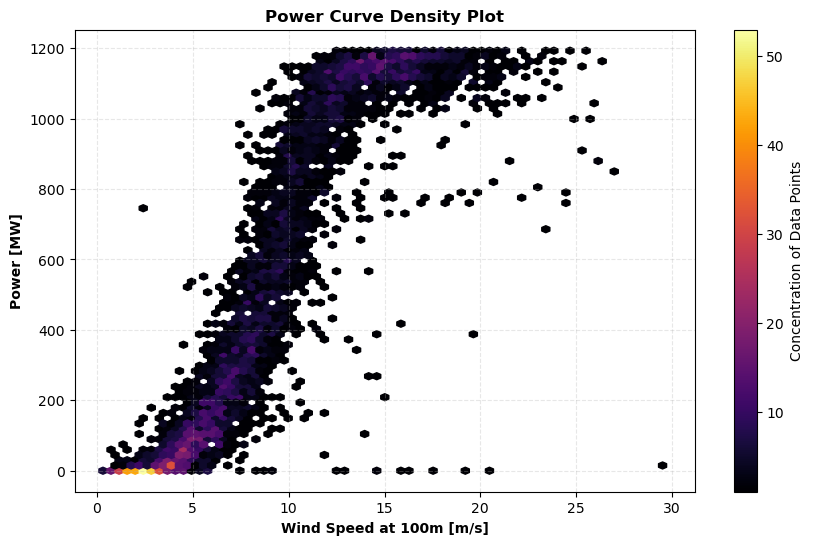

In [23]:
fig, ax = plt.subplots(figsize=(10,6))

hb = ax.hexbin(
    fresh_data['WindSpeed:100'], 
    fresh_data['Wind_MW'], 
    gridsize=70,        
    cmap='inferno',  
    mincnt=1
)

fig.colorbar(hb, ax=ax, label='Concentration of Data Points')

ax.set_title('Power Curve Density Plot',fontweight='bold')
ax.set_xlabel('Wind Speed at 100m [m/s]',fontweight='bold')
ax.set_ylabel('Power [MW]',fontweight='bold')
ax.grid(linestyle='--', alpha=0.3)
plt.savefig('unfiltered_plot.png',dpi=400)
plt.show()

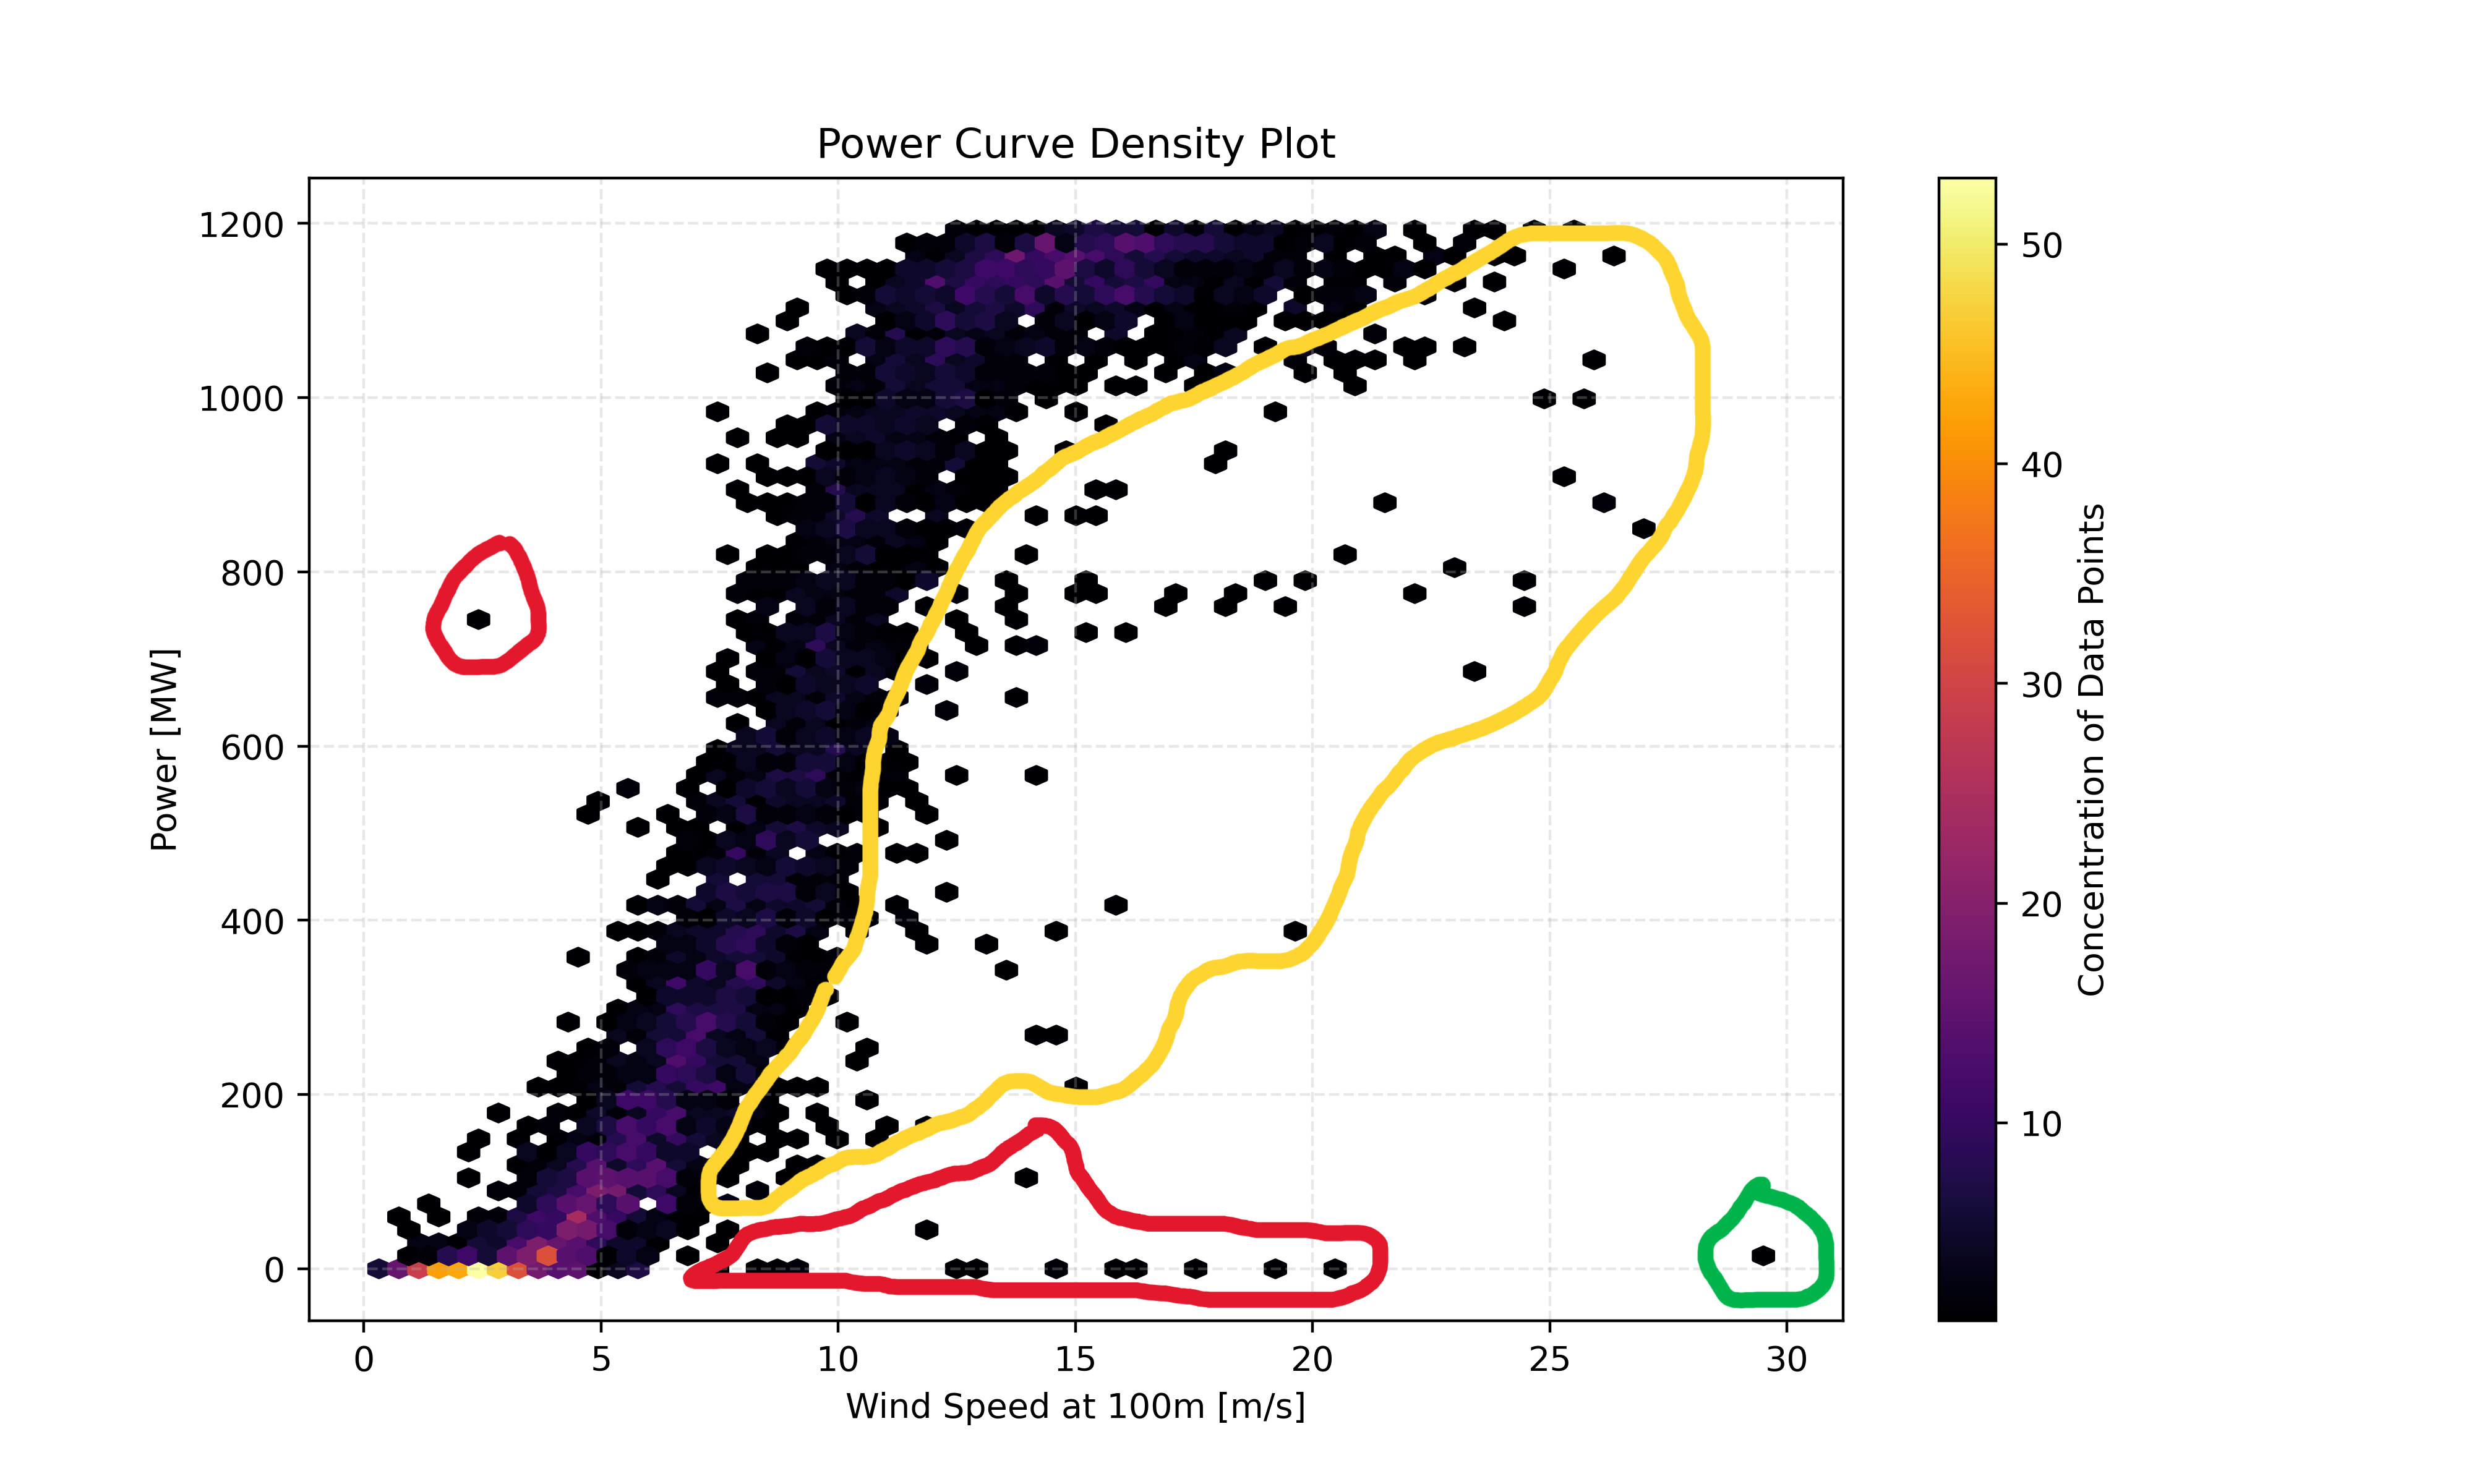

In [24]:
from IPython.display import Image, display

display(Image(filename='edited.png',width=800, height=600))

In [25]:
anomaly_mask = (wind_data_cleaned['WindSpeed:100'] > 5) & (wind_data_cleaned['WindSpeed:100'] < 25) & (wind_data_cleaned['Wind_MW'] < 20)
wind_data_cleaned = wind_data_cleaned[~anomaly_mask].reset_index(drop=True)

suspected = (wind_data_cleaned['WindSpeed:100'] < 5) & (wind_data_cleaned['Wind_MW'] > 400)
wind_data_cleaned = wind_data_cleaned[~suspected].reset_index(drop=True)

fresh_data = wind_data_cleaned.copy() # recent values

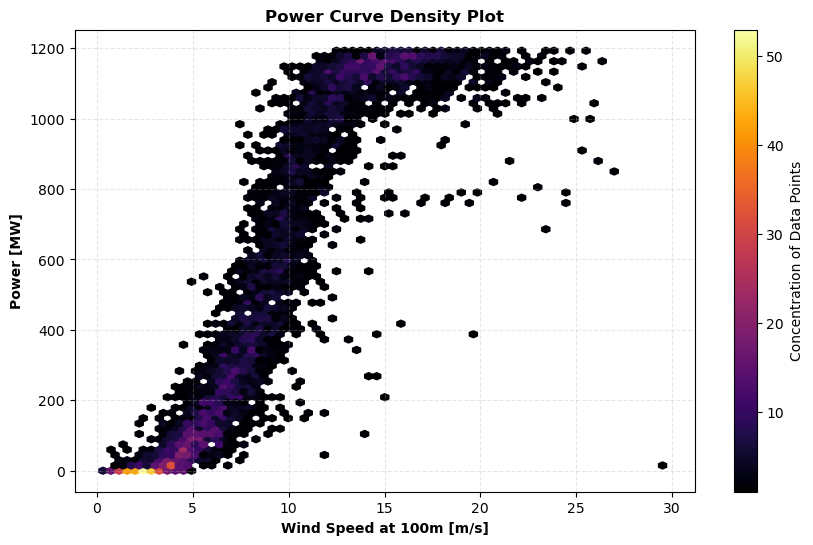

In [26]:
fig, ax = plt.subplots(figsize=(10,6))

hb = ax.hexbin(
    fresh_data['WindSpeed:100'], 
    fresh_data['Wind_MW'], 
    gridsize=70,        
    cmap='inferno',  
    mincnt=1
)

fig.colorbar(hb, ax=ax, label='Concentration of Data Points')

ax.set_title('Power Curve Density Plot',fontweight='bold')
ax.set_xlabel('Wind Speed at 100m [m/s]',fontweight='bold')
ax.set_ylabel('Power [MW]',fontweight='bold')
ax.grid(linestyle='--', alpha=0.3)
plt.savefig('filtered_plot.png',dpi=400)

plt.show()

In [27]:
wind_data_cleaned=wind_data_cleaned.copy()

### Feature Engineering

In [28]:
wind_data_cleaned['doy']=wind_data_cleaned['valid_datetime_abs'].dt.dayofyear
wind_data_cleaned['hour']=wind_data_cleaned['valid_datetime_abs'].dt.hour
wind_data_cleaned['month']=wind_data_cleaned['valid_datetime_abs'].dt.month

# Encoding months a year
wind_data_cleaned['sin_month']=np.sin(2*np.pi*wind_data_cleaned['month']/12)
wind_data_cleaned['cos_month']=np.cos(2*np.pi*wind_data_cleaned['month']/12)

# Encoding hours of days
wind_data_cleaned['sin_hour']=np.sin(2*np.pi*wind_data_cleaned['hour']/24)
wind_data_cleaned['cos_hour']=np.cos(2*np.pi*wind_data_cleaned['hour']/24)

# Encoding days of years
wind_data_cleaned['sin_doy']=np.sin(2*np.pi*wind_data_cleaned['doy']/365)
wind_data_cleaned['cos_doy']=np.cos(2*np.pi*wind_data_cleaned['doy']/365)

# Cubic relation
wind_data_cleaned['v_cube_100'] = wind_data_cleaned['WindSpeed:100'] **3
wind_data_cleaned['v_cube_ground'] = wind_data_cleaned['WindSpeed'] **3


wd_rad = wind_data_cleaned['WindDirection'] * np.pi / 180 #converting degree into radians
wd_rad_100 = wind_data_cleaned['WindDirection:100'] * np.pi / 180 

# Encoding wind direction at ground
wind_data_cleaned['wind_dir_sin'] = np.sin(wd_rad)
wind_data_cleaned['wind_dir_cos'] = np.cos(wd_rad)

# Encoding wind direction at 100m
wind_data_cleaned['wind_dir_sin_100'] = np.sin(wd_rad_100)
wind_data_cleaned['wind_dir_cos_100'] = np.cos(wd_rad_100)


# Features
features=['RelativeHumidity', 
          'Temperature',
          'WindSpeed', 
          'WindSpeed:100',
          'wind_dir_sin',
          'wind_dir_cos',
          'wind_dir_sin_100',
          'wind_dir_cos_100',
          'valid_datetime',
          'v_cube_100',
          'sin_month',
          'cos_month'
         ]

### Separating inputs and target

In [29]:
split_point = int(len(wind_data_cleaned) * 0.8)

train_df = wind_data_cleaned.iloc[:split_point]
test_df = wind_data_cleaned.iloc[split_point:]

X_train = train_df[features]
y_train = train_df['Wind_MW']
X_test = test_df[features]
y_test = test_df['Wind_MW']

# for horizon check
train_horizon=merged_wind_horizon.iloc[:split_point]
df_test_horizon=merged_wind_horizon.iloc[split_point:]
X_test_horizon = df_test_horizon[features]
y_test_horizon=df_test_horizon['Wind_MW']



### Training using recent values only

In [30]:
X_train_0h=X_train.copy()
y_train_0h=y_train.copy()

### Training a Quantile Model

In [31]:
from sklearn.ensemble import GradientBoostingRegressor

def train_q(q):
    model=GradientBoostingRegressor(loss='quantile',alpha=q)
    model.fit(X_train_0h,y_train_0h)
    return model

steps=np.linspace(0.1,0.9,9)
models_0h={}
for q in steps:
    models_0h[q]=train_q(q)


In [32]:
steps=np.linspace(0.1,0.9,9)

### Saving the models

In [33]:
import joblib
joblib.dump(models_0h, "quantile_models.pkl")

['quantile_models.pkl']

### Importing the model

In [34]:
models_0h = joblib.load("quantile_models.pkl")

X_test_clean = X_test.copy().reset_index(drop=True)
wind_data_test = test_df.copy().reset_index(drop=True)

for q in models_0h.keys():
    wind_data_test[f"pred_q{int(q*100)}"] = pd.NA

unique_horizons = sorted(X_test_clean['valid_datetime'].unique())

for h in unique_horizons:
    horizon_mask = X_test_clean['valid_datetime'] == h
    
    X_test_h = X_test_clean[horizon_mask]
    
    for q, model in models_0h.items():
        predictions = model.predict(X_test_h)
        
        wind_data_test.loc[horizon_mask, f"pred_q{int(q*100)}"] = predictions

### Result Visualisation

### Pinball Loss

### Pinball Loss Formula

For a given target quantile $q \in (0, 1)$, the Pinball Loss $\mathcal{L}_q$ for a true value $y$ and a predicted value $\hat{y}$ is defined as:

$$
\mathcal{L}_q(y, \hat{y}) = \max \Big( q(y - \hat{y}), \, (q - 1)(y - \hat{y}) \Big)
$$

Alternatively, it can be written as a piecewise function:

$$
\mathcal{L}_q(y, \hat{y}) = 
\begin{cases} 
q(y - \hat{y}) & \text{if } y \geq \hat{y} \quad \text{(Underestimation)} \\
(q - 1)(y - \hat{y}) & \text{if } y < \hat{y} \quad \text{(Overestimation)}
\end{cases}
$$

C:\Users\esaya\AppData\Local\Temp\ipykernel_15012\3620893652.py:20: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ks-" (-> color='k'). The keyword argument will take precedence.
  ax.plot(quantiles, losses_single_h, 'ks-', lw=1.5, color='purple')
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


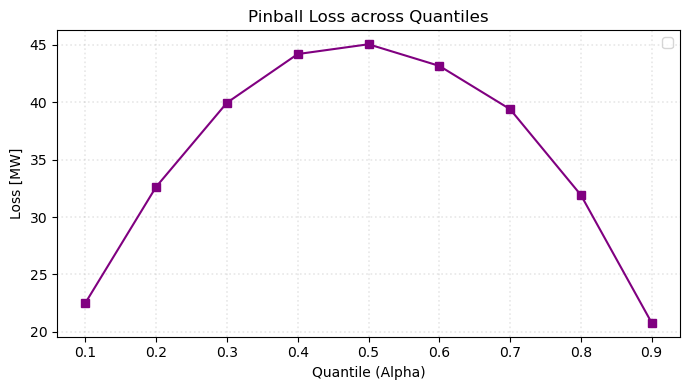

In [35]:

models_0h = joblib.load("quantile_models.pkl")

def pinball_loss(y_true, y_pred, q):
    diff = y_true - y_pred
    return np.mean(np.maximum(q * diff, (q - 1) * diff))

X_test_clean = X_test.copy().reset_index(drop=True)
y_test_clean = y_test.copy().reset_index(drop=True)

quantiles = sorted(list(models_0h.keys()))
losses_single_h = []

for q in quantiles:
    y_pred = models_0h[q].predict(X_test)
    loss = pinball_loss(y_test, y_pred, q)
    losses_single_h.append(loss)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(quantiles, losses_single_h, 'ks-', lw=1.5, color='purple')

ax.set_title("Pinball Loss across Quantiles")
ax.set_xlabel("Quantile (Alpha)")
ax.set_ylabel("Loss [MW]")
ax.set_xticks(quantiles)

ax.grid(True, alpha=0.3, linewidth=1.2, linestyle=':')
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

### Pinball Loss Across Horizons 

In [36]:
horizons_to_test = [0, 6, 12, 18, 24, 36, 48]
horizon_results = {}

for h in horizons_to_test:
    X_test_h = X_test_horizon[X_test_horizon['valid_datetime'] == h].reset_index(drop=True)
    y_test_h = y_test_horizon[X_test_horizon['valid_datetime'] == h].reset_index(drop=True)
    
    h_losses = []
    for q in steps:
        y_pred = models_0h[q].predict(X_test_h)
        h_losses.append(pinball_loss(y_test_h, y_pred, q))
        
    horizon_results[h] = np.mean(h_losses)

In [37]:
horizons = list(horizon_results.keys())
losses_by_horizon = list(horizon_results.values())

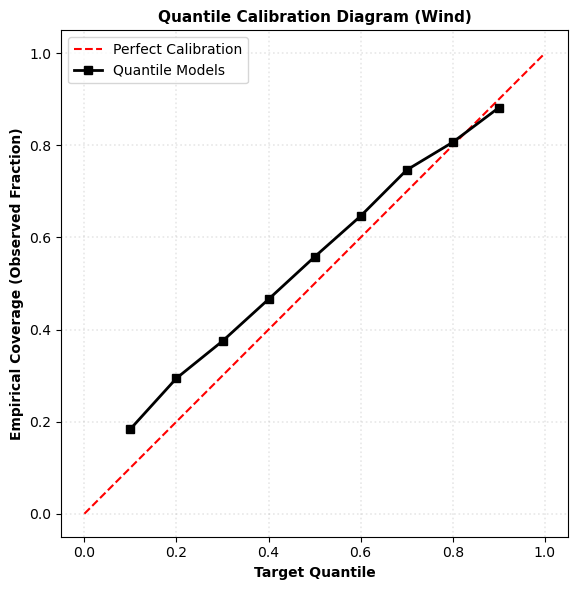

In [38]:
models_0h = joblib.load("quantile_models.pkl")

X_test_clean = X_test.copy().reset_index(drop=True)
y_test_clean = y_test.copy().reset_index(drop=True)

X_test_clean['valid_datetime'] = X_test_clean['valid_datetime'].astype(int)

target_horizon = 0  

horizon_mask = X_test_clean['valid_datetime'] == target_horizon
X_test_single_h = X_test_clean[horizon_mask]
y_test_single_h = y_test_clean[horizon_mask]

steps = sorted(list(models_0h.keys()))
empirical_frequencies = []

for q in steps:
    y_pred = models_0h[q].predict(X_test_single_h)
    
    actual_fraction = np.mean(y_test_single_h <= y_pred)
    empirical_frequencies.append(actual_fraction)

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot([0, 1], [0, 1], 'r--', lw=1.5, label='Perfect Calibration')

ax.plot(steps, empirical_frequencies, 'ks-', lw=2, label=f'Quantile Models')

ax.set_title(f"Quantile Calibration Diagram (Wind)", fontsize=11, fontweight='bold')
ax.set_xlabel("Target Quantile",fontweight='bold')
ax.set_ylabel("Empirical Coverage (Observed Fraction)",fontweight='bold')
ax.set_xlim([-0.05, 1.05])
ax.set_ylim([-0.05, 1.05])

ax.grid(True, alpha=0.3, linewidth=1.2, linestyle=':')
ax.legend(loc='upper left')

ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.savefig('calibration.png',dpi=400)
plt.show()

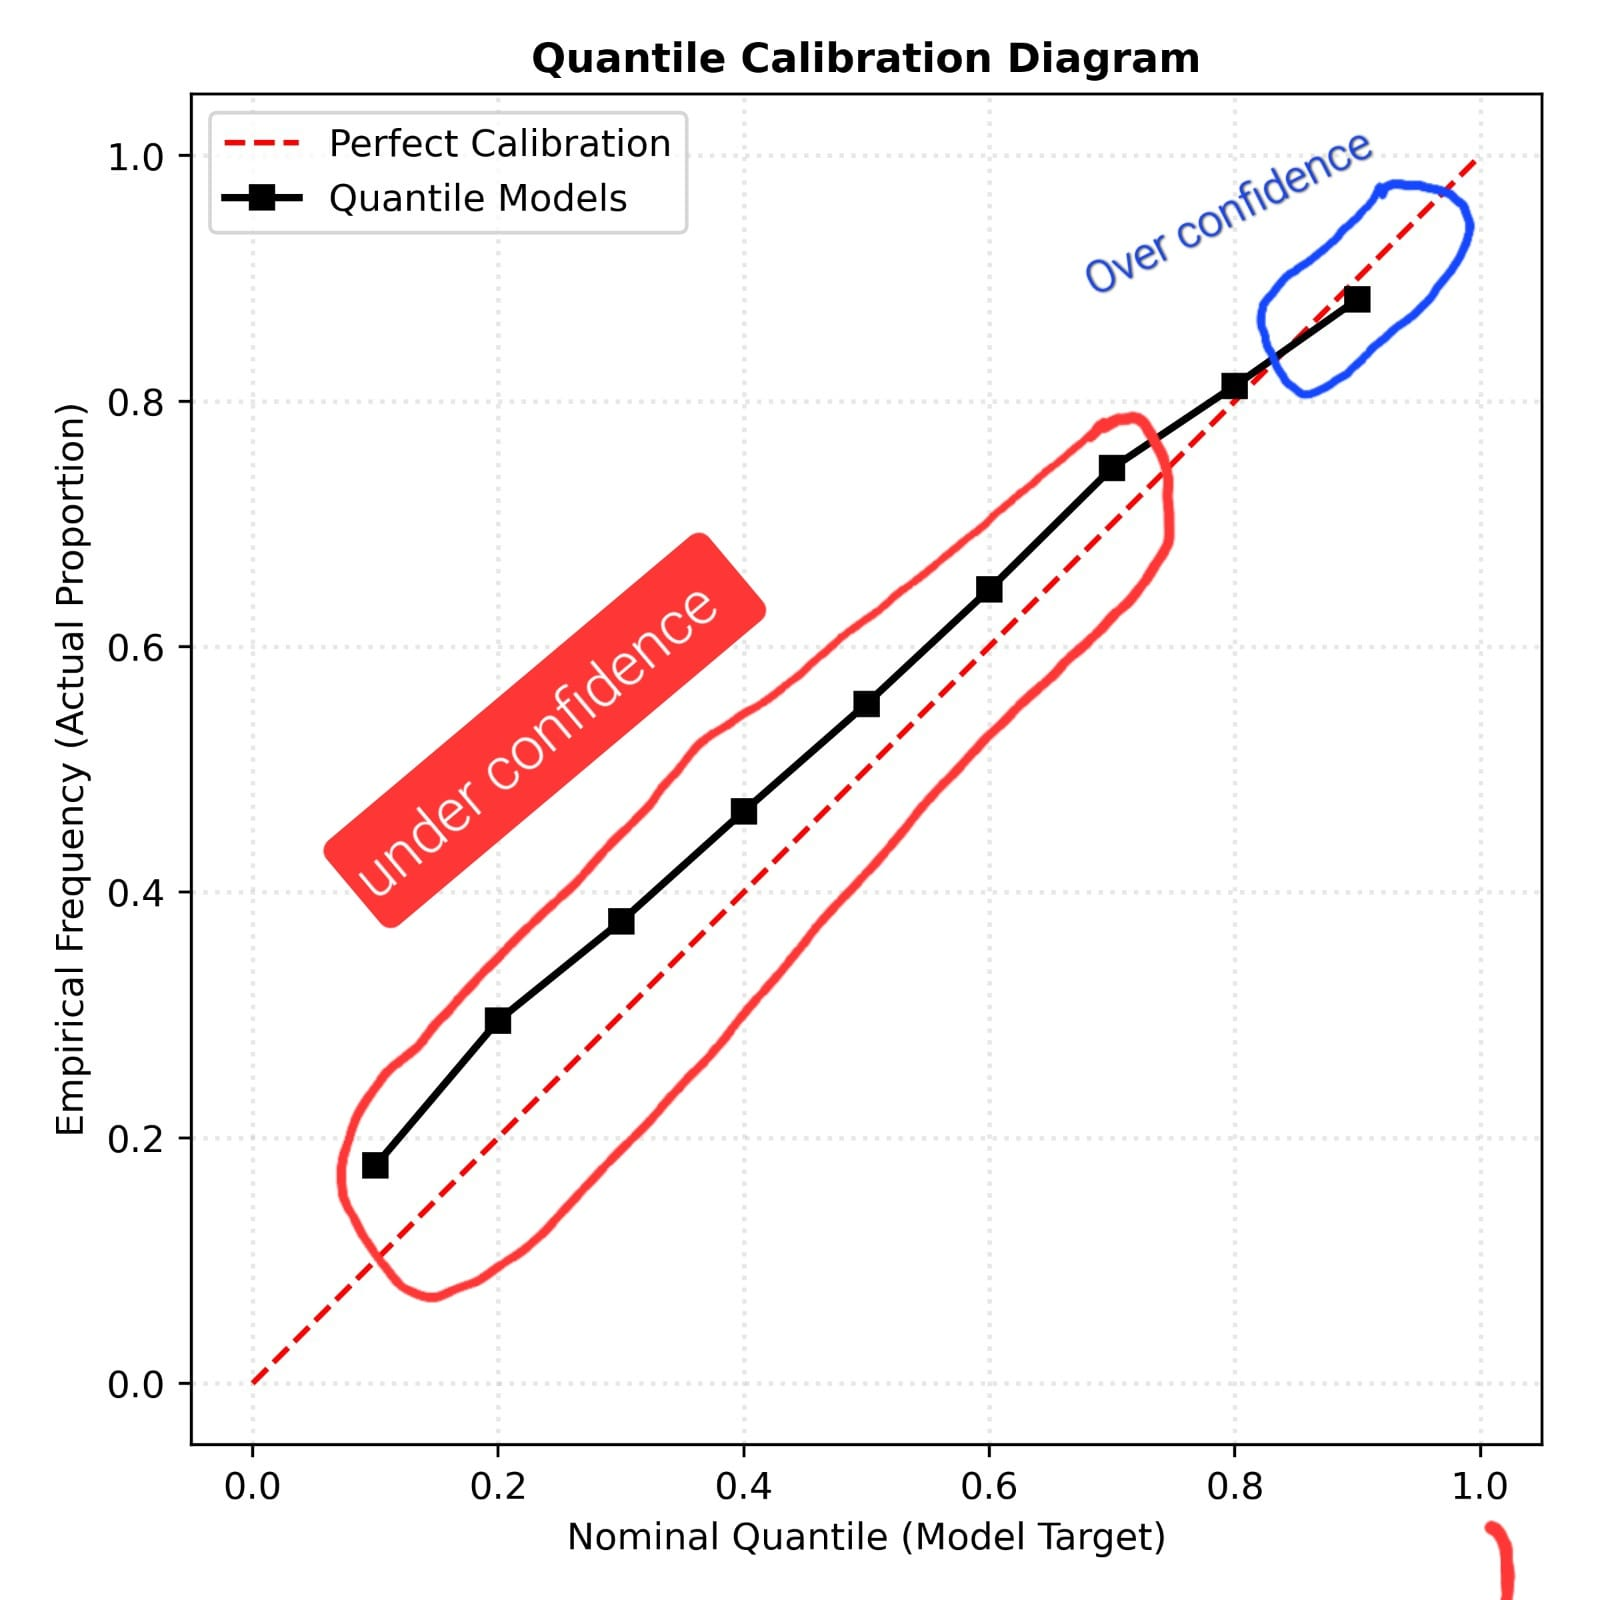

In [39]:
display(Image('calibration_edited.png',width=600,height=400))

### Grid operators use this number to understand their worst-case scenario. 
- If the 10th percentile says $200\text{ MW}$, they know they can safely count on at least $200\text{ MW}$ of clean energy flowing into the grid.

### Wind Speed Regimes

C:\Users\esaya\AppData\Local\Temp\ipykernel_15012\2160783182.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


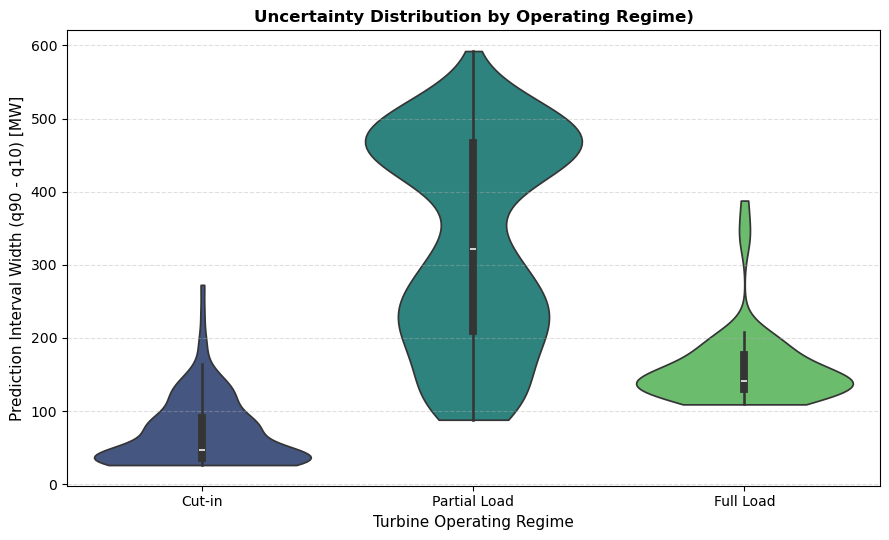

In [40]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

wind_data_test['interval_width'] = wind_data_test['pred_q90'] - wind_data_test['pred_q10']
target_horizon = 0 

wind_data_regime_subset = wind_data_test[wind_data_test['valid_datetime'] == target_horizon].copy()

bins = [0, 3, 12, 25]
labels = ['Cut-in', 'Partial Load', 'Full Load']

wind_data_regime_subset['regime'] = pd.cut(
    wind_data_regime_subset['WindSpeed'], 
    bins=bins, 
    labels=labels
)

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.violinplot(
    data=wind_data_regime_subset, 
    x='regime', 
    y='interval_width', 
    palette='viridis', 
    inner='box',
    cut=0,
    ax=ax
)

ax.set_title(
    f'Uncertainty Distribution by Operating Regime)', 
    fontsize=12, 
    fontweight='bold'
)
ax.set_xlabel('Turbine Operating Regime', fontsize=11)
ax.set_ylabel('Prediction Interval Width (q90 - q10) [MW]', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

### Observation 
- Our analysis confirms that uncertainty propagation is highest in the Partial Load regime. While the Cut-in and Full Load regimes show narrower intervals. Here, the cubic relationship between wind and power amplifies small meteorological forecast errors into large power production uncertainties.

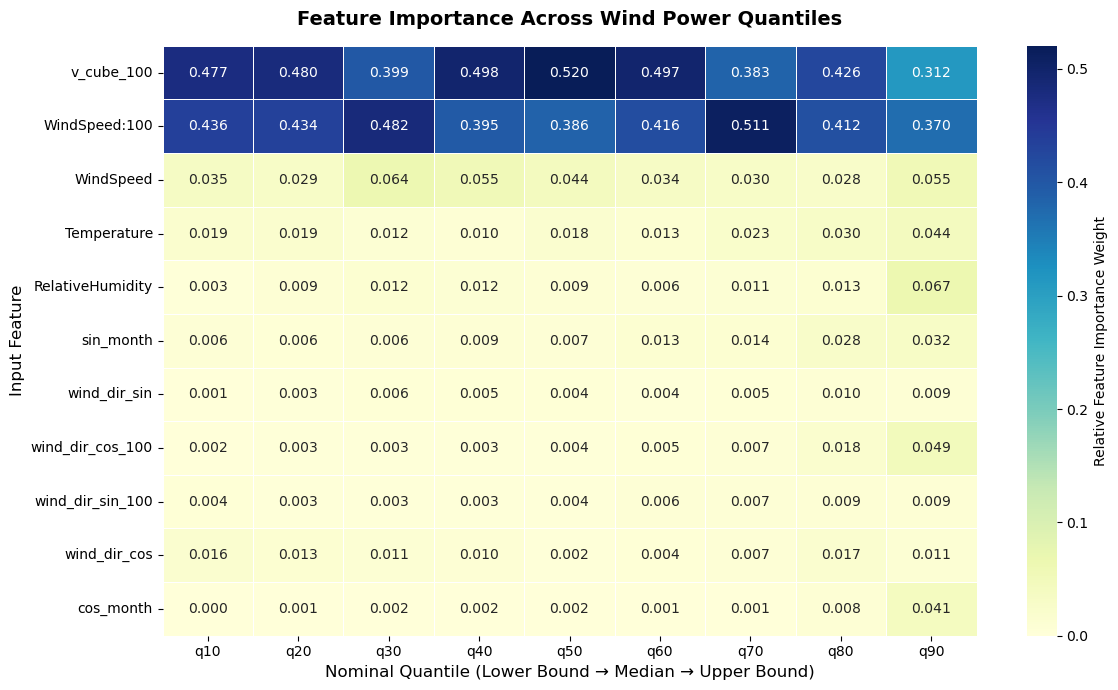

In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

importance_df = pd.DataFrame(
    {f"q{int(q*100)}": model.feature_importances_ for q, model in models_0h.items()},
    index=X_test.columns
)

importance_df.index.name = 'Feature'

if 'valid_datetime' in importance_df.index:
    importance_df = importance_df.drop(index='valid_datetime')

if 'q50' in importance_df.columns:
    importance_df = importance_df.sort_values(by='q50', ascending=False)

fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    importance_df,
    annot=True, 
    fmt=".3f", 
    cmap="YlGnBu", 
    linewidths=0.5, 
    cbar_kws={'label': 'Relative Feature Importance Weight'},
    ax=ax
)

ax.set_title("Feature Importance Across Wind Power Quantiles", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Nominal Quantile (Lower Bound → Median → Upper Bound)", fontsize=12)
ax.set_ylabel("Input Feature", fontsize=12)

plt.tight_layout()
plt.show()

### Uncertaiinty Distribution 

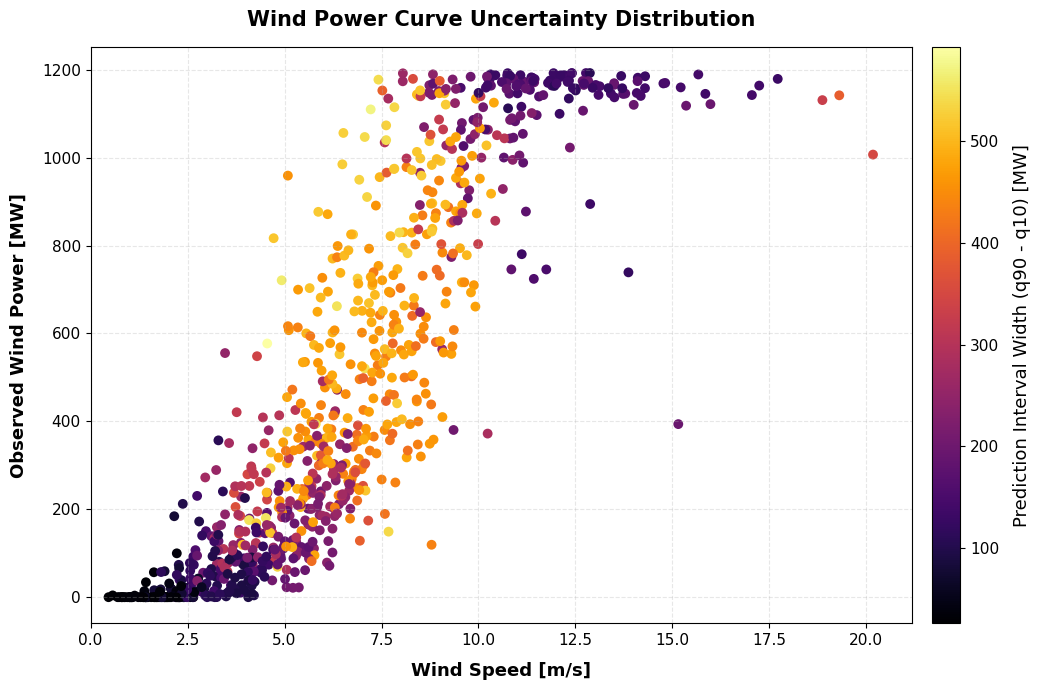

In [42]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

wind_data_regime_subset = wind_data_test[wind_data_test['valid_datetime'] == 0].copy()
wind_data_regime_subset['interval_width'] = wind_data_regime_subset['pred_q90'] - wind_data_regime_subset['pred_q10']


plot_data = wind_data_regime_subset.dropna(subset=['WindSpeed', 'Wind_MW', 'interval_width']).copy()

fig, ax = plt.subplots(figsize=(11, 7))

sc = ax.scatter(
    plot_data['WindSpeed'], 
    plot_data['Wind_MW'], 
    c=plot_data['interval_width'], 
    cmap='inferno',      
    s=50,                 
    edgecolors='none'
)


cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label('Prediction Interval Width (q90 - q10) [MW]', fontsize=13, labelpad=10)
cbar.ax.tick_params(labelsize=11)

ax.set_title('Wind Power Curve Uncertainty Distribution', fontsize=15, pad=15,fontweight='bold')
ax.set_xlabel('Wind Speed [m/s]', fontsize=13, labelpad=10,fontweight='bold')
ax.set_ylabel('Observed Wind Power [MW]', fontsize=13, labelpad=10,fontweight='bold')

ax.tick_params(axis='both', labelsize=11)

ax.set_xlim(0, plot_data['WindSpeed'].max() + 1)
ax.grid(True, linestyle='--', alpha=0.3)

fig.tight_layout()
fig.savefig('uncertainty_distribution.png', dpi=300)
plt.show()

### Conversion Baseline and Weather-Forecast Uncertainty

Common timestamps per horizon: 877


,horizon,mean_pinball_loss,additional_weather_degradation
0,0,35.579,0.000
1,6,38.164,2.586
2,12,42.471,6.892
3,18,45.013,9.434
4,24,48.928,13.349
5,36,55.974,20.395
6,48,63.938,28.360


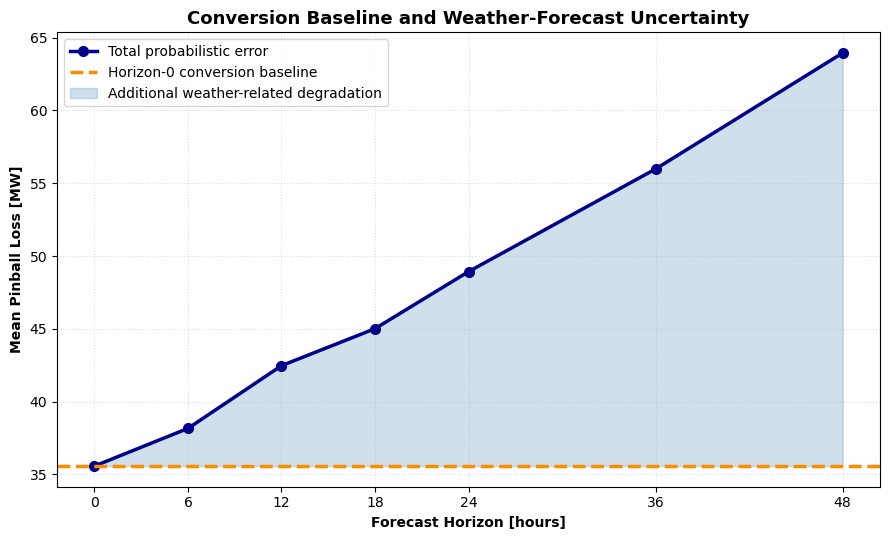

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

horizons = [0, 6, 12, 18, 24, 36, 48]
quantiles = sorted(models_0h.keys())


def pinball_loss(y_true, y_pred, q):
    error = y_true - y_pred

    return np.mean(
        np.maximum(
            q * error,
            (q - 1) * error
        )
    )


# Use the chronological horizon-0 test timestamps
test_times = pd.Index(
    test_df["valid_datetime_abs"].dropna().unique()
)

evaluation_data = merged_wind_horizon[
    merged_wind_horizon["valid_datetime"].isin(horizons)
    & merged_wind_horizon["valid_datetime_abs"].isin(test_times)
].dropna(
    subset=features + ["Wind_MW"]
).copy()


# Keep only timestamps available at every horizon
availability = (
    evaluation_data
    .groupby("valid_datetime_abs")["valid_datetime"]
    .nunique()
)

common_times = availability[
    availability == len(horizons)
].index

evaluation_data = evaluation_data[
    evaluation_data["valid_datetime_abs"].isin(common_times)
].copy()

print(f"Common timestamps per horizon: {len(common_times)}")


# Calculate mean pinball loss at every horizon
results = []

for horizon in horizons:

    horizon_data = evaluation_data[
        evaluation_data["valid_datetime"] == horizon
    ].sort_values("valid_datetime_abs")

    X_horizon = horizon_data[features]
    y_actual = horizon_data["Wind_MW"].to_numpy()

    losses = []

    for q in quantiles:

        y_predicted = models_0h[q].predict(X_horizon)

        loss = pinball_loss(
            y_actual,
            y_predicted,
            q
        )

        losses.append(loss)

    results.append({
        "horizon": horizon,
        "mean_pinball_loss": np.mean(losses)
    })


results = pd.DataFrame(results)

# Horizon 0 is the approximate conversion-uncertainty baseline
conversion_baseline = results.loc[
    results["horizon"] == 0,
    "mean_pinball_loss"
].iloc[0]

results["additional_weather_degradation"] = (
    results["mean_pinball_loss"]
    - conversion_baseline
)

display(results.round(3))


# Plot the comparison in one graph
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    results["horizon"],
    results["mean_pinball_loss"],
    marker="o",
    markersize=7,
    linewidth=2.5,
    color="darkblue",
    label="Total probabilistic error"
)

ax.axhline(
    conversion_baseline,
    color="darkorange",
    linestyle="--",
    linewidth=2.5,
    label="Horizon-0 conversion baseline"
)

ax.fill_between(
    results["horizon"],
    conversion_baseline,
    results["mean_pinball_loss"],
    where=(
        results["mean_pinball_loss"]
        >= conversion_baseline
    ),
    color="steelblue",
    alpha=0.25,
    label="Additional weather-related degradation"
)

ax.set_title(
    "Conversion Baseline and Weather-Forecast Uncertainty",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Forecast Horizon [hours]",fontweight='bold')
ax.set_ylabel("Mean Pinball Loss [MW]",fontweight='bold')
ax.set_xticks(horizons)

ax.grid(
    True,
    linestyle=":",
    alpha=0.4
)

ax.legend()

plt.tight_layout()

plt.savefig(
    "wind_uncertainty_decomposition_pinball.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Solar related dataset

In [44]:
import xarray as xr
import pandas as pd
ds_solar=xr.open_dataset("dwd_icon_eu_pes10_20200920_20231027.nc")
ds_solar

<xarray.Dataset> Size: 133MB
Dimensions:                 (ref_datetime: 4467, valid_datetime: 93, point: 20)
Coordinates:
    latitude                (point) float64 160B ...
    longitude               (point) float64 160B ...
  * point                   (point) int64 160B 0 1 2 3 4 5 ... 14 15 16 17 18 19
  * ref_datetime            (ref_datetime) datetime64[ns] 36kB 2020-09-20 ......
  * valid_datetime          (valid_datetime) int64 744B 0 1 2 3 ... 114 117 120
Data variables:
    CloudCover              (ref_datetime, valid_datetime, point) float32 33MB ...
    SolarDownwardRadiation  (ref_datetime, valid_datetime, point) float64 66MB ...
    Temperature             (ref_datetime, valid_datetime, point) float32 33MB ...

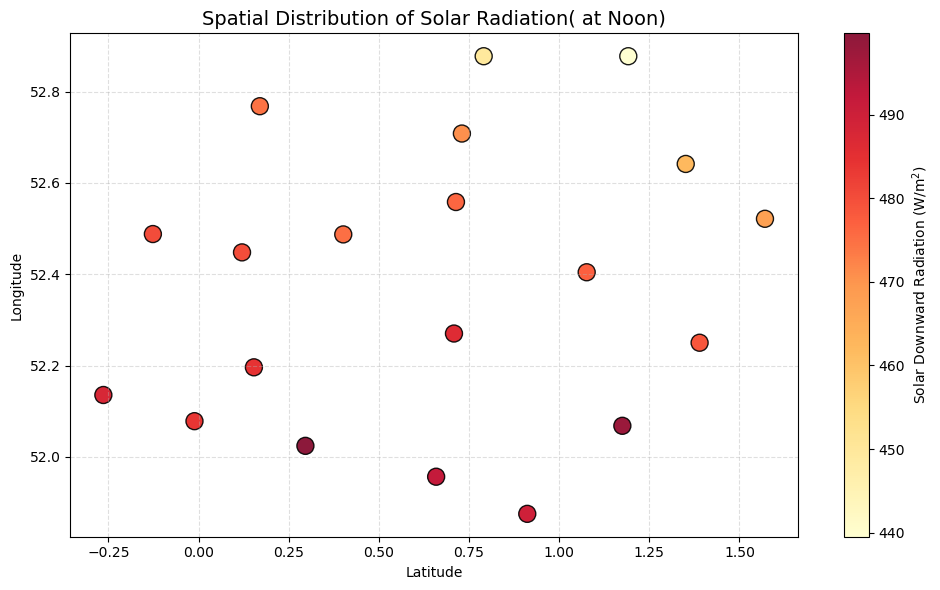

In [45]:
lat=ds_solar.latitude.data
lon=ds_solar.longitude.data
irr=ds_solar.SolarDownwardRadiation.data
irr_0=irr[2,0,:]

import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,6))
sc=ax.scatter(lon,lat,c=irr_0, cmap='YlOrRd',
               s=150, edgecolor='k', alpha=0.9)
fig.colorbar(sc, ax=ax, label=r'Solar Downward Radiation ($\mathrm{W/m}^2$)')
ax.set_xlabel('Latitude')
ax.set_ylabel('Longitude')
ax.set_title('Spatial Distribution of Solar Radiation( at Noon)', fontsize=14)
ax.grid(True, linestyle='--',alpha=0.4)
plt.tight_layout()
plt.show()



In [46]:
lat_0, lon_0 = lat[0], lon[0]
print(f'lat={lat_0}, lon={lon_0}')

lat=52.4872562, lon=0.4012455


### Keeping recent values only and taking a spatial mean across the 20 locations

In [47]:
df_solar_weather=ds_solar.mean(dim='point').to_dataframe().reset_index().copy()
df_solar_weather


,ref_datetime,valid_datetime,CloudCover,SolarDownwardRadiation,Temperature
0,2020-09-20,0,0.450405,0.000000,13.646173
1,2020-09-20,1,0.494018,0.000000,13.670843
2,2020-09-20,2,0.546410,0.000000,13.793360
3,2020-09-20,3,0.627071,0.000000,13.907354
4,2020-09-20,4,0.681062,0.000000,14.022113
...,...,...,...,...,...
415426,2023-10-27,108,0.810468,180.746119,12.455963
415427,2023-10-27,111,0.459340,23.697193,12.856787
415428,2023-10-27,114,0.069910,0.976647,10.006506
415429,2023-10-27,117,0.652018,0.932845,8.682965


In [48]:
df_solar_weather['datetime_abs']=df_solar_weather['ref_datetime'] + pd.to_timedelta(df_solar_weather['valid_datetime'],unit='h')
df_solar_weather['datetime_abs']=df_solar_weather['datetime_abs'].dt.tz_localize('UTC')

In [49]:
df_solar_power=pd.read_csv('Energy_Data_20200920_20231027.csv')
df_solar_power.index=pd.to_datetime(df_solar_power['dtm'])
df_solar_power.drop(columns='dtm',inplace=True)

In [50]:
df_solar_power

,MIP,Solar_MW,Solar_capacity_mwp,Solar_installedcapacity_mwp,Wind_MW,SS_Price,boa_MWh,DA_Price
dtm,,,,,,,,
2020-09-19 23:00:00+00:00,24.05,0.0,2108.489754,2206.064655,1034.700,2.50,0.0,34.62
2020-09-19 23:30:00+00:00,13.44,0.0,2108.489754,2206.064655,1002.292,2.00,0.0,34.62
2020-09-20 00:00:00+00:00,20.06,0.0,2108.489754,2206.064655,996.284,2.50,0.0,33.08
2020-09-20 00:30:00+00:00,19.77,0.0,2108.489754,2206.064655,957.576,15.00,0.0,33.08
2020-09-20 01:00:00+00:00,28.68,0.0,2108.489754,2206.064655,941.044,47.95,0.0,32.17
...,...,...,...,...,...,...,...,...
2023-10-26 21:30:00+00:00,97.82,0.0,2331.438485,2487.180474,NaN,NaN,NaN,98.47
2023-10-26 22:00:00+00:00,104.34,0.0,2331.438485,2487.180474,NaN,NaN,NaN,97.32
2023-10-26 22:00:00+00:00,104.34,0.0,2331.438485,2487.180474,NaN,NaN,NaN,97.32


In [51]:
df_solar_power=df_solar_power[['Solar_MW','Solar_capacity_mwp','Solar_installedcapacity_mwp']].copy()

In [52]:
df_solar_power=df_solar_power.resample(rule='1h').mean()

In [53]:
df_solar_power=df_solar_power.reset_index().copy()

In [54]:
df_solar_merged=pd.merge(df_solar_weather,df_solar_power,
                         left_on='datetime_abs',right_on='dtm',how='inner')

In [55]:
df_solar_merged=df_solar_merged.dropna().copy() # simply drop NAN values

In [56]:
df_solar_merged=df_solar_merged.sort_values(['ref_datetime','valid_datetime']).copy() # sorting using the forecast issue time

In [57]:
df_solar_merged=df_solar_merged[df_solar_merged['valid_datetime']==0].copy()

In [58]:
df_solar_merged

,ref_datetime,valid_datetime,CloudCover,SolarDownwardRadiation,Temperature,datetime_abs,dtm,Solar_MW,Solar_capacity_mwp,Solar_installedcapacity_mwp
0,2020-09-20 00:00:00,0,0.450405,0.000000,13.646173,2020-09-20 00:00:00+00:00,2020-09-20 00:00:00+00:00,0.000000,2108.489754,2206.064655
7,2020-09-20 06:00:00,0,0.675504,50.268750,13.815460,2020-09-20 06:00:00+00:00,2020-09-20 06:00:00+00:00,61.345972,2108.489754,2206.064655
20,2020-09-20 12:00:00,0,0.422889,477.627728,19.447498,2020-09-20 12:00:00+00:00,2020-09-20 12:00:00+00:00,1227.354845,2108.489754,2206.064655
39,2020-09-20 18:00:00,0,0.279009,0.000000,16.119684,2020-09-20 18:00:00+00:00,2020-09-20 18:00:00+00:00,0.000023,2108.444662,2206.067896
64,2020-09-21 00:00:00,0,0.399281,0.000000,12.391174,2020-09-21 00:00:00+00:00,2020-09-21 00:00:00+00:00,0.000000,2108.444662,2206.067896
...,...,...,...,...,...,...,...,...,...,...
413817,2023-10-25 18:00:00,0,0.411774,0.000000,8.667364,2023-10-25 18:00:00+00:00,2023-10-25 18:00:00+00:00,0.000000,2331.492943,2487.180474
413910,2023-10-26 00:00:00,0,1.000000,0.000000,6.995965,2023-10-26 00:00:00+00:00,2023-10-26 00:00:00+00:00,0.000000,2331.438485,2487.180474
414003,2023-10-26 06:00:00,0,0.983769,0.379688,10.047796,2023-10-26 06:00:00+00:00,2023-10-26 06:00:00+00:00,0.000054,2331.438485,2487.180474
414096,2023-10-26 12:00:00,0,0.939792,113.358594,12.084173,2023-10-26 12:00:00+00:00,2023-10-26 12:00:00+00:00,385.031618,2331.438485,2487.180474


### Removing night values

In [59]:
df_solar_merged['Solar_Capacity_Factor'] = df_solar_merged['Solar_MW']/df_solar_merged['Solar_capacity_mwp']

time_index=pd.DatetimeIndex(df_solar_merged['datetime_abs'])
if time_index.tz is None:
    time_index=time_index.tz_localize('UTC')

In [60]:
import pvlib

solpos=pvlib.solarposition.get_solarposition(time=time_index,
                                             latitude=lat_0,
                                             longitude=lon_0,)
solpos

,apparent_zenith,zenith,apparent_elevation,elevation,azimuth,equation_of_time
datetime_abs,,,,,,
2020-09-20 00:00:00+00:00,126.490319,126.490319,-36.490319,-36.490319,2.542180,6.574068
2020-09-20 06:00:00+00:00,87.747752,88.030784,2.252248,1.969216,91.091192,6.662625
2020-09-20 12:00:00+00:00,51.694929,51.716204,38.305071,38.283796,182.660457,6.751120
2020-09-20 18:00:00+00:00,90.129859,90.727663,-0.129859,-0.727663,272.103539,6.839548
2020-09-21 00:00:00+00:00,126.876387,126.876387,-36.876387,-36.876387,2.665839,6.927904
...,...,...,...,...,...,...
2023-10-25 18:00:00+00:00,102.298753,102.298753,-12.298753,-12.298753,265.931936,15.931003
2023-10-26 00:00:00+00:00,139.634492,139.634492,-49.634492,-49.634492,6.631817,15.959484
2023-10-26 06:00:00+00:00,97.136516,97.136516,-7.136516,-7.136516,101.025001,15.987222


In [61]:
df_solar_merged['zenith']=solpos['zenith'].values # adding the zenith column

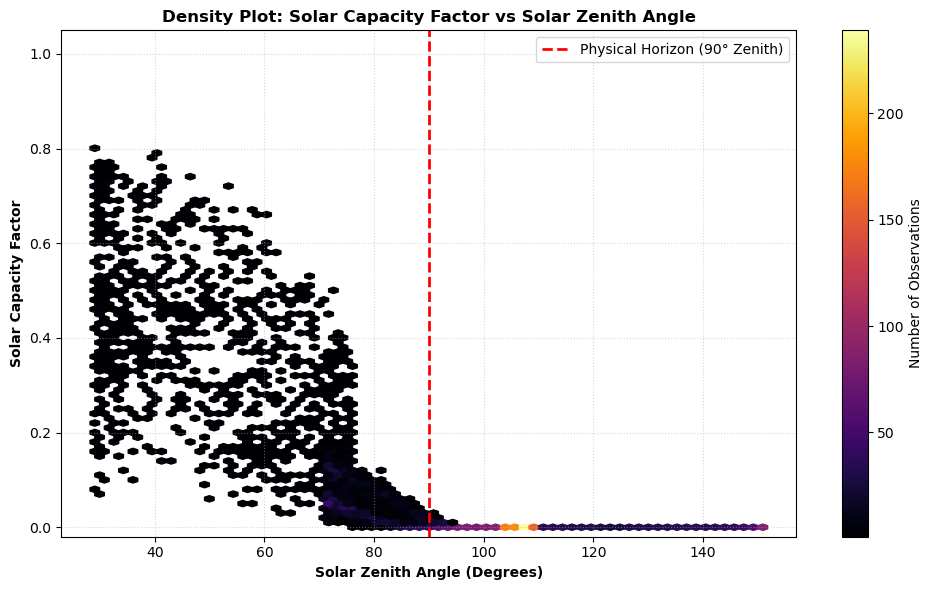

 Data Filtering Summary
Total original rows (with night): 4453
Total daytime rows (after filter): 2153
Rows removed: 2300


In [62]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

hb = ax.hexbin(
    df_solar_merged['zenith'],
    df_solar_merged['Solar_Capacity_Factor'],
    gridsize=70,
    cmap='inferno',
    mincnt=1
)

# Physical horizon line
ax.axvline(
    x=90,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Physical Horizon (90° Zenith)'
)

cb = fig.colorbar(hb, ax=ax)
cb.set_label('Number of Observations')

ax.set_xlabel('Solar Zenith Angle (Degrees)',fontweight='bold')
ax.set_ylabel('Solar Capacity Factor',fontweight='bold')
ax.set_title('Density Plot: Solar Capacity Factor vs Solar Zenith Angle',fontweight='bold')

ax.set_ylim(-0.02, 1.05)

ax.legend()
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('verification_plot.png',dpi=400)
plt.show()

df_solar_daytime = df_solar_merged[df_solar_merged['zenith'] < 88].copy()

print(" Data Filtering Summary")
print(f"Total original rows (with night): {len(df_solar_merged)}")
print(f"Total daytime rows (after filter): {len(df_solar_daytime)}")
print(f"Rows removed: {len(df_solar_merged) - len(df_solar_daytime)}")

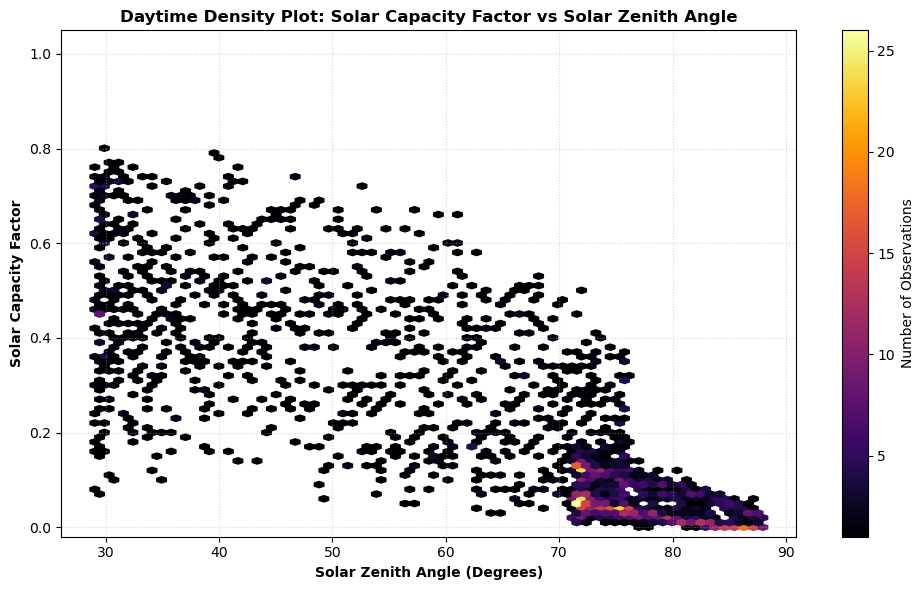

Data Filtering Summary
Total original rows (with night): 4453
Total daytime rows (after filter): 2153
Rows removed: 2300


In [63]:
import matplotlib.pyplot as plt

# keep only daytime
df_solar_daytime = df_solar_merged[
    df_solar_merged['zenith'] < 88
].copy()

fig, ax = plt.subplots(figsize=(10, 6))

hb = ax.hexbin(
    df_solar_daytime['zenith'],
    df_solar_daytime['Solar_Capacity_Factor'],
    gridsize=70,
    cmap='inferno',
    mincnt=1
)

cb = fig.colorbar(hb, ax=ax)
cb.set_label('Number of Observations')

ax.set_xlabel('Solar Zenith Angle (Degrees)',fontweight='bold')
ax.set_ylabel('Solar Capacity Factor',fontweight='bold')
ax.set_title('Daytime Density Plot: Solar Capacity Factor vs Solar Zenith Angle',fontweight='bold')

ax.set_ylim(-0.02, 1.05)
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('verification_plot_daytime.png', dpi=400)
plt.show()

print("Data Filtering Summary")
print(f"Total original rows (with night): {len(df_solar_merged)}")
print(f"Total daytime rows (after filter): {len(df_solar_daytime)}")
print(f"Rows removed: {len(df_solar_merged) - len(df_solar_daytime)}")

In [64]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
import joblib

# features
features = ['SolarDownwardRadiation', 'CloudCover', 'Temperature', 'zenith'] 
target = 'Solar_Capacity_Factor'

df_solar_daytime = df_solar_daytime.dropna(subset=features + [target]).copy()

# Chronological Split
split_point = int(len(df_solar_daytime) * 0.8)

train_df = df_solar_daytime.iloc[:split_point]
test_df = df_solar_daytime.iloc[split_point:]

X_train_0h = train_df[features]
y_train_0h = train_df[target]

X_test_0h = test_df[features]
y_test_0h = test_df[target]

# training function
def train_q(q):
    print(f"Training Solar Model for quantile: {q:.1f}")
    model = GradientBoostingRegressor(loss='quantile', alpha=q, random_state=42)
    model.fit(X_train_0h, y_train_0h)
    return model

steps = np.linspace(0.1, 0.9, 9)
models_0h = {}
for q in steps:
    models_0h[q] = train_q(q)

# Save the trained solar dictionary
joblib.dump(models_0h, "solar_quantile_models.pkl")

Training Solar Model for quantile: 0.1
Training Solar Model for quantile: 0.2
Training Solar Model for quantile: 0.3
Training Solar Model for quantile: 0.4
Training Solar Model for quantile: 0.5
Training Solar Model for quantile: 0.6
Training Solar Model for quantile: 0.7
Training Solar Model for quantile: 0.8
Training Solar Model for quantile: 0.9


['solar_quantile_models.pkl']

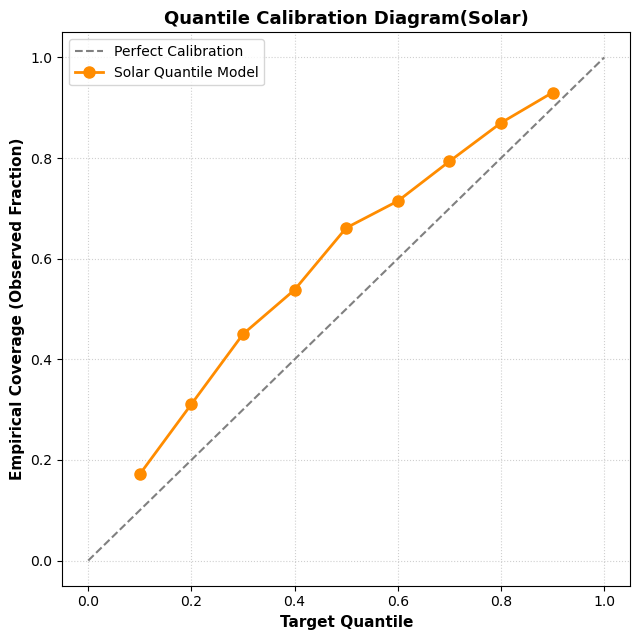

In [ ]:
solar_results = test_df.copy()

empirical_coverages = []
for q in steps:
    col_name = f'pred_q{int(q*100)}'
    solar_results[col_name] = models_0h[q].predict(X_test_0h)
    solar_results[col_name] = solar_results[col_name].clip(lower=0, upper=1)
    
    # Calculate coverage
    coverage = (solar_results[target] < solar_results[col_name]).mean()
    empirical_coverages.append(coverage)



fig, ax = plt.subplots(figsize=(6.5, 6.5))

ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5, label='Perfect Calibration')

ax.plot(steps, empirical_coverages, color='darkorange', linestyle='-', marker='o', 
        markersize=8, linewidth=2, label='Quantile Model')

# Customizing Plot
ax.set_title('Quantile Calibration Diagram(Solar)', fontsize=13, fontweight='bold')
ax.set_xlabel('Target Quantile', fontsize=11,fontweight='bold')
ax.set_ylabel('Empirical Coverage (Observed Fraction)', fontsize=11,fontweight='bold')
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', fontsize=10)

fig.tight_layout()
fig.savefig('solar_quantiles_calibration.png', dpi=400)
plt.show()

Estimated Wind Farm Capacity: 1192.54 MW
Mean Solar Interval Width: 0.1465
Mean Wind Interval Width:  0.2377
Number of Solar Data Points: 431
Number of Wind Data Points:  880


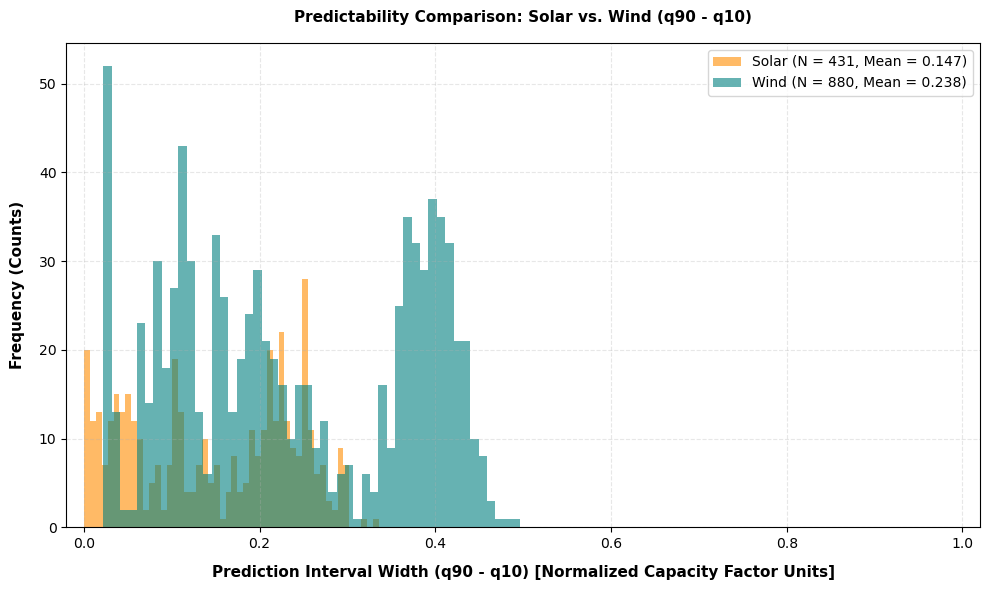

In [66]:

wind_capacity = wind_data_test['Wind_MW'].max()
print(f"Estimated Wind Farm Capacity: {wind_capacity:.2f} MW")


wind_data_test['actual_CF_wind'] = wind_data_test['Wind_MW'] / wind_capacity

# Scale the wind quantile predictions (q10 and q90)
wind_data_test['pred_q90_normalized'] = wind_data_test['pred_q90'] / wind_capacity
wind_data_test['pred_q10_normalized'] = wind_data_test['pred_q10'] / wind_capacity

# Clip to physical bounds [0, 1]
wind_data_test['pred_q90_normalized'] = wind_data_test['pred_q90_normalized'].clip(lower=0, upper=1)
wind_data_test['pred_q10_normalized'] = wind_data_test['pred_q10_normalized'].clip(lower=0, upper=1)


solar_results['interval_width'] = solar_results['pred_q90'] - solar_results['pred_q10']
wind_data_test['interval_width'] = wind_data_test['pred_q90_normalized'] - wind_data_test['pred_q10_normalized']

mean_solar_width = solar_results['interval_width'].mean()
mean_wind_width = wind_data_test['interval_width'].mean()

print(f"Mean Solar Interval Width: {mean_solar_width:.4f}")
print(f"Mean Wind Interval Width:  {mean_wind_width:.4f}")

# data points for each dataset
n_solar = len(solar_results['interval_width'])
n_wind = len(wind_data_test['interval_width'])

print(f"Number of Solar Data Points: {n_solar}")
print(f"Number of Wind Data Points:  {n_wind}")


fig, ax = plt.subplots(figsize=(10, 6))

# Plot histograms with N included in the legend
ax.hist(
    solar_results['interval_width'], 
    bins=50, 
    alpha=0.6, 
    label=f'Solar (N = {n_solar:,}, Mean = {mean_solar_width:.3f})', 
    color='darkorange', 
    density=False
)
ax.hist(
    wind_data_test['interval_width'], 
    bins=50, 
    alpha=0.6, 
    label=f'Wind (N = {n_wind:,}, Mean = {mean_wind_width:.3f})', 
    color='teal', 
    density=False
)

ax.set_title('Predictability Comparison: Solar vs. Wind (q90 - q10)', fontsize=11, pad=15,fontweight='bold')
ax.set_xlabel('Prediction Interval Width (q90 - q10) [Normalized Capacity Factor Units]', fontsize=11, labelpad=10,fontweight='bold')
ax.set_ylabel('Frequency (Counts)', fontsize=11, labelpad=10,fontweight='bold')
ax.set_xlim(-0.02, 1.02)
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(fontsize=10, loc='upper right')

fig.tight_layout()
fig.savefig('predictability_comparison_9_quantiles_normalized.png', dpi=300)
plt.show()

In [67]:
# for the whole dataset
# uncertainty for solar